In [ ]:

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.lines as mliness
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd


In [2]:
lon_min, lon_max, lat_min, lat_max = 8, 25, -41, -34
extent = [lon_min, lon_max, lat_min, lat_max]

CRUISE_START = "2026-05-14"
CRUISE_END   = "2026-07-27"

ft = 10
vmin, vmax = -1, 1
levels = np.arange(vmin, vmax + 0.01, 0.01)

###### PATHS ######
BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
### Here I am using SSH, but you can replace this with any satellite data for SST, Phytoplankton etc
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = BASE / "data/TOEDDIES/TOEDDIES_better_ADT"
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"

crs = ccrs.PlateCarree()
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max) / 2)

# Bathymetry
bathymetry_data = xr.open_dataset(FNAME_BATHY)
lon_subset = bathymetry_data["lon"].sel(lon=slice(lon_min, lon_max))
lat_subset = bathymetry_data["lat"].sel(lat=slice(lat_min, lat_max))
depth_subset = bathymetry_data["topo"].sel(lon=slice(lon_min, lon_max),
                                           lat=slice(lat_min, lat_max))

# File lists
daily_ssh_files = sorted(os.listdir(DIR_SSH))
eddy_files_better = sorted(os.listdir(DIR_EDDIES))

In [3]:
###### FUNCTIONS ######
def load_satellite(adt_path):
    ds = xr.open_dataset(adt_path)
    if "time" in ds:
        ds = ds.drop_vars("time")
    ds.close()
    return {
        "dataset": ds,
        "lon": ds.longitude,
        "lat": ds.latitude,
        "adt": ds.adt,
        "ugos": np.squeeze(ds.ugos),
        "vgos": np.squeeze(ds.vgos)
    }

def get_eddy_files(date_compact, date):
    """Use the better-ADT TOEddies when available for that day, else the standard ones."""
    files = [DIR_EDDIES / f for f in eddy_files_better if date_compact in f]
    return files, "TOEddies (better ADT)"

def setup_map(ax, extent, title, crs, ft):
    """Apply common formatting to Cartopy maps."""

    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.set_title(title)

    ax.add_feature(
        cfeature.LAND,
        linewidth=0.5,
        edgecolor="black",
        facecolor="gray",
        zorder=4
    )

    ax.coastlines(
        resolution="10m",
        color="k",
        zorder=5
    )

    grid = ax.gridlines(
        draw_labels=True,
        linewidth=1,
        color="black",
        alpha=0.2,
        linestyle="--",
        zorder=6
    )

    grid.top_labels = False
    grid.right_labels = False
    grid.left_labels = True
    grid.xlabel_style = {"size": ft}
    grid.ylabel_style = {"size": ft}

def load_eddies(dir_eddies):
    """Load cyclonic and anticyclonic eddy shapefiles."""

    anti = {}
    cyc = {}

    for fname in dir_eddies:

        if "anti" in str(fname):
            target = anti
        else:
            target = cyc

        if "maxspeed" in str(fname):
            target["maxspeed"] = gpd.read_file(fname)

        elif "outcontour" in str(fname):
            target["outcontour"] = gpd.read_file(fname)

        elif "centers" in str(fname):
            target["centers"] = gpd.read_file(fname)

    return anti, cyc

def plot_eddies(ax, eddies, color, crs):

    ms = eddies["maxspeed"]
    oc = eddies["outcontour"]
    cent = eddies["centers"]

    for i in range(len(cent)):

        if ms.geometry[i] is None:
            continue

        x, y = ms.geometry[i].exterior.xy
        ax.plot(x, y, color=color, transform=crs, zorder=20)

        x, y = oc.geometry[i].exterior.xy
        ax.plot(
            x,
            y,
            "--",
            color=color,
            transform=crs,
            zorder=20
        )

        ax.scatter(
            cent.geometry[i].x,
            cent.geometry[i].y,
            s=10,
            color=color,
            transform=crs,
            zorder=20,
        )

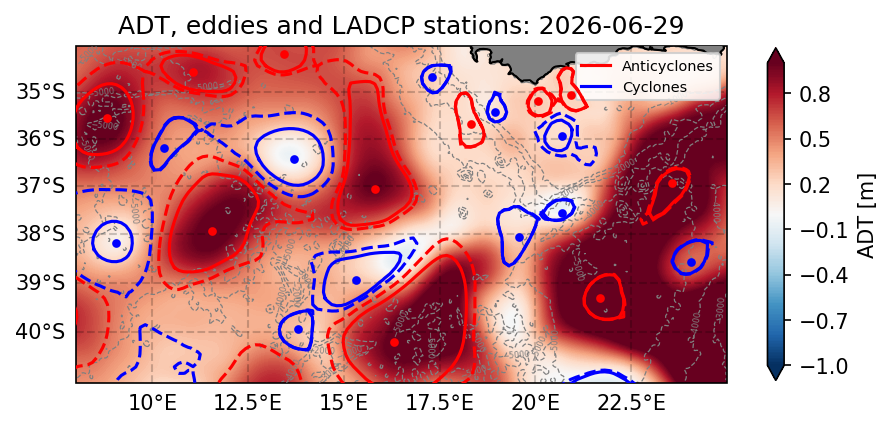

In [4]:
###### PLOTTING ######
date = "2026-06-29"
date_str = date
date_compact = date.replace("-", "")

# --- ADT of the day ---
ssh_match = [f for f in daily_ssh_files if date_str in f or date_compact in f]

ssh = load_satellite(DIR_SSH / ssh_match[0])

# --- Eddies of the day ---
eddy_files, eddy_source = get_eddy_files(date_compact, date_str)

# Fixed figure size and no bbox_inches="tight" so all frames are identical in size
fig = plt.figure(figsize=(7, 4.8), dpi=150)
ax = fig.add_subplot(111, projection=proj)
setup_map(ax, extent, f"ADT, eddies and LADCP stations: {date_str}", crs, ft)

bathy = ax.contour(lon_subset, lat_subset, depth_subset,
                    colors="grey", linewidths=0.6, transform=crs)
ax.clabel(bathy, fontsize=4)

c = ax.contourf(ssh["lon"], ssh["lat"], ssh["adt"][0],
                levels=levels, cmap="RdBu_r", extend="both",
                transform=crs)

if eddy_files:
    anti, cyc = load_eddies(eddy_files)
    plot_eddies(ax, anti, "red", crs)
    plot_eddies(ax, cyc, "blue", crs)
else:
    warnings.warn(f"No eddy file for {date_str} in either TOEddies folder.")

# --- Legend (proxy handles, so it is the same on every frame) ---
handles = [
    mlines.Line2D([], [], color="red", label="Anticyclones"),
    mlines.Line2D([], [], color="blue", label="Cyclones"),
]
ax.legend(handles=handles, fontsize="x-small", loc="upper right",
            framealpha=0.85)

cb = fig.colorbar(c, ax=ax, shrink=0.6, ticks=np.arange(vmin, vmax + 0.01, 0.3))
cb.set_label("ADT [m]")
plt.show()
